In [4]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.cluster import KMeans

In [2]:
df = pd.read_csv("Iris.csv")
df.head()

,Id,SepalLengthCm,SepalWidthCm,PetalLengthCm,PetalWidthCm,Species
0,1,5.1,3.5,1.4,0.2,Iris-setosa
1,2,4.9,3.0,1.4,0.2,Iris-setosa
2,3,4.7,3.2,1.3,0.2,Iris-setosa
3,4,4.6,3.1,1.5,0.2,Iris-setosa
4,5,5.0,3.6,1.4,0.2,Iris-setosa


In [3]:
X = df[["SepalLengthCm", "SepalWidthCm", "PetalLengthCm", "PetalWidthCm"]]
print("Features Shape:", X.shape)
print("Actual Species:", df["Species"].unique())

Features Shape: (150, 4)
Actual Species: ['Iris-setosa' 'Iris-versicolor' 'Iris-virginica']


In [5]:
model = KMeans(n_clusters=3, random_state=42, n_init=10)
df["Cluster"] = model.fit_predict(X)
print(df["Cluster"].value_counts())

Cluster
0    62
1    50
2    38
Name: count, dtype: int64


In [6]:
comparison = pd.crosstab(df["Species"], df["Cluster"])
print(comparison)

Cluster           0   1   2
Species                    
Iris-setosa       0  50   0
Iris-versicolor  48   0   2
Iris-virginica   14   0  36


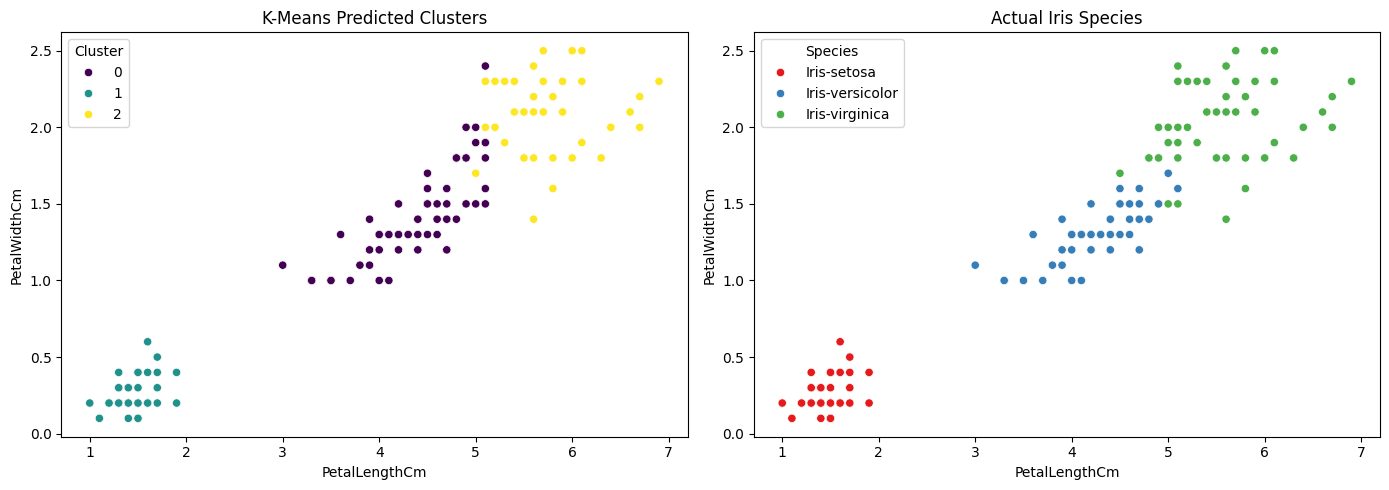

In [8]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Plot 1: K-Means Clusters
sns.scatterplot( data=df, x="PetalLengthCm", y="PetalWidthCm", hue="Cluster", palette="viridis", ax=axes[0])

axes[0].set_title("K-Means Predicted Clusters")

# Plot 2: Actual Species
sns.scatterplot(data=df, x="PetalLengthCm", y="PetalWidthCm", hue="Species", palette="Set1", ax=axes[1])

axes[1].set_title("Actual Iris Species")
plt.tight_layout()
plt.show()